<a href="https://colab.research.google.com/github/ZiadSakr5/ZezoSakr/blob/main/EV_efficiency_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## Task 1 — Dataset Selection and Exploration

I selected the **Electric Vehicles Specifications 2025** dataset. Each row is one EV variant with battery, performance, charging and size specifications.

### The target: what is `efficiency_wh_per_km`?

`efficiency_wh_per_km` is the **energy consumption** of the car: how many **watt-hours (Wh) of battery energy it uses to drive one kilometre**. It is the electric-car equivalent of "litres per 100 km" for a petrol car.

### Turning the target into classes

`efficiency_wh_per_km` is a number, but this assignment evaluates the model with **accuracy and a classification report**, which need class labels. So the number is split into three equal-sized groups (tertiles): **Efficient**, **Average** and **Inefficient** (Task 2).

In [ ]:
df = pd.read_csv("electric_vehicles_spec_2025_csv.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (478, 22)


,brand,model,top_speed_kmh,battery_capacity_kWh,battery_type,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,fast_charging_power_kw_dc,fast_charge_port,towing_capacity_kg,cargo_volume_l,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,source_url
0,Abarth,500e Convertible,155,37.8,Lithium-ion,192.0,235.0,156,225,7.0,67.0,CCS,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1904/Abarth-500e-C...
1,Abarth,500e Hatchback,155,37.8,Lithium-ion,192.0,235.0,149,225,7.0,67.0,CCS,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1903/Abarth-500e-H...
2,Abarth,600e Scorpionissima,200,50.8,Lithium-ion,102.0,345.0,158,280,5.9,79.0,CCS,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3057/Abarth-600e-S...
3,Abarth,600e Turismo,200,50.8,Lithium-ion,102.0,345.0,158,280,6.2,79.0,CCS,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3056/Abarth-600e-T...
4,Aiways,U5,150,60.0,Lithium-ion,NaN,310.0,156,315,7.5,78.0,CCS,NaN,496,5,FWD,JC - Medium,4680,1865,1700,SUV,https://ev-database.org/car/1678/Aiways-U5


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 478 entries, 0 to 477
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand                      478 non-null    str    
 1   model                      477 non-null    str    
 2   top_speed_kmh              478 non-null    int64  
 3   battery_capacity_kWh       478 non-null    float64
 4   battery_type               478 non-null    str    
 5   number_of_cells            276 non-null    float64
 6   torque_nm                  471 non-null    float64
 7   efficiency_wh_per_km       478 non-null    int64  
 8   range_km                   478 non-null    int64  
 9   acceleration_0_100_s       478 non-null    float64
 10  fast_charging_power_kw_dc  477 non-null    float64
 11  fast_charge_port           477 non-null    str    
 12  towing_capacity_kg         452 non-null    float64
 13  cargo_volume_l             477 non-null    str    
 14  seats

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
top_speed_kmh,478.0,185.487448,34.252773,125.0,160.0,180.00,201.00,325.0
battery_capacity_kWh,478.0,74.043724,20.331058,21.3,60.0,76.15,90.60,118.0
number_of_cells,276.0,485.293478,1210.819733,72.0,150.0,216.00,324.00,7920.0
torque_nm,471.0,498.012739,241.461128,113.0,305.0,430.00,679.00,1350.0
efficiency_wh_per_km,478.0,162.903766,34.317532,109.0,143.0,155.00,177.75,370.0
range_km,478.0,393.179916,103.287335,135.0,320.0,397.50,470.00,685.0
acceleration_0_100_s,478.0,6.882636,2.730696,2.2,4.8,6.60,8.20,19.1
fast_charging_power_kw_dc,477.0,125.008386,58.205012,29.0,80.0,113.00,150.00,281.0
towing_capacity_kg,452.0,1052.261062,737.851774,0.0,500.0,1000.00,1600.00,2500.0
seats,478.0,5.263598,1.003961,2.0,5.0,5.00,5.00,9.0


In [ ]:
# Missing values and odd columns
missing = df.isna().sum()
missing_report = pd.DataFrame({"missing": missing, "missing_%": (missing / len(df) * 100).round(1)})
print(missing_report[missing_report["missing"] > 0])
print("\nUnique values in battery_type:", df["battery_type"].unique())
print("Values of fast_charge_port:\n", df["fast_charge_port"].value_counts(dropna=False))
print("\ncargo_volume_l values that are not plain numbers:")
print(df.loc[pd.to_numeric(df["cargo_volume_l"], errors="coerce").isna(), "cargo_volume_l"].tolist())

                           missing  missing_%
model                            1        0.2
number_of_cells                202       42.3
torque_nm                        7        1.5
fast_charging_power_kw_dc        1        0.2
fast_charge_port                 1        0.2
towing_capacity_kg              26        5.4
cargo_volume_l                   1        0.2

Unique values in battery_type: <StringArray>
['Lithium-ion']
Length: 1, dtype: str
Values of fast_charge_port:
 fast_charge_port
CCS        476
CHAdeMO      1
NaN          1
Name: count, dtype: int64

cargo_volume_l values that are not plain numbers:
['10 Banana Boxes', nan, '31 Banana Boxes', '13 Banana Boxes']


count    478.0
mean     162.9
std       34.3
min      109.0
25%      143.0
50%      155.0
75%      177.8
max      370.0
Name: efficiency_wh_per_km, dtype: float64


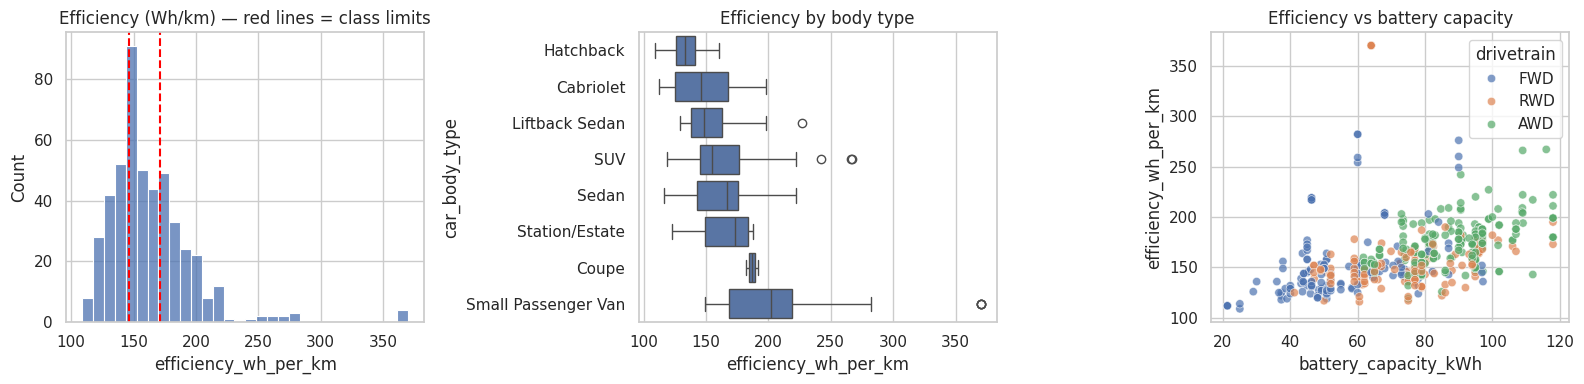

In [ ]:
# The target: efficiency_wh_per_km
print(df["efficiency_wh_per_km"].describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["efficiency_wh_per_km"], bins=30, ax=axes[0])
for cut in df["efficiency_wh_per_km"].quantile([1/3, 2/3]):
    axes[0].axvline(cut, color="red", linestyle="--")
axes[0].set_title("Efficiency (Wh/km) — red lines = class limits")

order = df.groupby("car_body_type")["efficiency_wh_per_km"].median().sort_values().index
sns.boxplot(data=df, y="car_body_type", x="efficiency_wh_per_km", order=order, ax=axes[1])
axes[1].set_title("Efficiency by body type")

sns.scatterplot(data=df, x="battery_capacity_kWh", y="efficiency_wh_per_km", hue="drivetrain", alpha=0.7, ax=axes[2])
axes[2].set_title("Efficiency vs battery capacity")

plt.tight_layout()
plt.show()

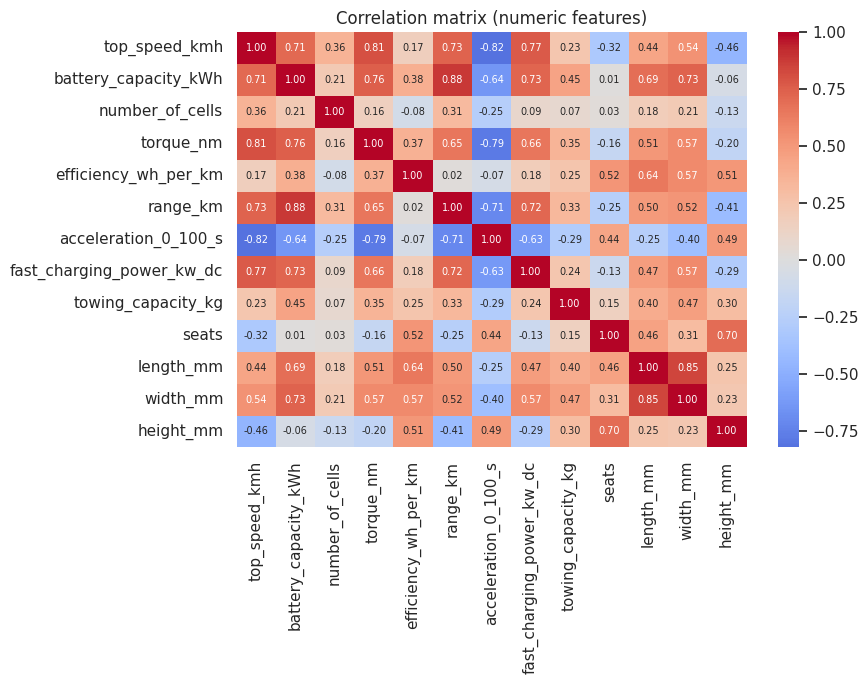

In [ ]:
# Correlation between numeric features
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()

In [ ]:
# Is range_km a safe input? Range is (usable battery energy) / (energy used per km), so battery capacity and
# range together almost give the efficiency directly.
implied = df["battery_capacity_kWh"] * 1000 / df["range_km"]
print("Correlation of efficiency_wh_per_km with range_km alone:", round(df["efficiency_wh_per_km"].corr(df["range_km"]), 2))
print("Correlation of efficiency_wh_per_km with battery_capacity / range:", round(df["efficiency_wh_per_km"].corr(implied), 2))

Correlation of efficiency_wh_per_km with range_km alone: 0.02
Correlation of efficiency_wh_per_km with battery_capacity / range: 0.83


**Exploration findings**

- 478 rows and 22 columns. `efficiency_wh_per_km` has no missing values and ranges from 109 to 370 Wh/km (median about 155).
- Efficiency differs clearly between body types: hatchbacks are the most efficient (median about 133 Wh/km), SUVs sit in the middle (about 155), and sedans, station wagons and especially small passenger vans use the most energy per kilometre (about 202 for vans). All-wheel-drive cars also use more energy (median about 174 Wh/km) than front-wheel-drive ones (about 145). Efficiency rises with battery capacity as well, because larger, heavier cars carry bigger batteries.
- `battery_type` is constant and `fast_charge_port` is almost constant (476 of 477 are CCS), so neither can help a model.
- `number_of_cells` is missing for about 42% of the rows, which is too much to impute reliably.
- `cargo_volume_l` is stored as text because a few entries are written like "10 Banana Boxes".
- `model` and `source_url` are unique identifiers, and one row has no `model` value.
- A few numeric columns (`torque_nm`, `towing_capacity_kg`, `fast_charging_power_kw_dc`) have a small number of missing values.
- **`range_km` must be excluded.** On its own it is almost unrelated to efficiency, but battery capacity divided by range is strongly correlated with it (about 0.83), because range is calculated from the battery energy and the energy used per kilometre. Using range as an input would let the model "calculate" the answer instead of predicting it from the car's design, so it is removed.

## Task 2 — Data Preprocessing

Steps applied:

1. **Fix the data type** of `cargo_volume_l` (convert to numeric; the few "Banana Boxes" entries become missing values).
2. **Create the target.** Split `efficiency_wh_per_km` into three equal-sized classes: **Efficient** (lowest consumption), **Average** and **Inefficient** (highest consumption).
3. **Drop columns that cannot help generalisation or would leak the answer:** identifiers (`model`, `source_url`), constant or near-constant columns (`battery_type`, `fast_charge_port`), the mostly-empty `number_of_cells`, and `range_km` (see Task 1).
4. **Remove duplicate rows** (variants identical in every remaining column), so the same row cannot land in both the training and testing set.
5. **Handle missing values** with imputation: median for numeric columns, most-frequent value for categorical columns.
6. **Scale numeric features** with `StandardScaler`.
7. **Encode categorical features** (`brand`, `drivetrain`, `segment`, `car_body_type`) with one-hot encoding.

Steps 5–7 are wrapped in a scikit-learn `ColumnTransformer`. It is *fitted on the training data only* (after the split in Task 3), so no information from the test set leaks into preprocessing.

In [ ]:
data = df.copy()

# 1. Fix data type
data["cargo_volume_l"] = pd.to_numeric(data["cargo_volume_l"], errors="coerce")

# 2. Target: three equal-sized efficiency classes (lower Wh/km = more efficient)
data["efficiency_class"] = pd.qcut(data["efficiency_wh_per_km"], q=3, labels=["Efficient", "Average", "Inefficient"])
edges = data["efficiency_wh_per_km"].quantile([0, 1/3, 2/3, 1])
print("Class limits (Wh/km):")
print(f"  Efficient   : {edges.iloc[0]:.0f} - {edges.iloc[1]:.0f}")
print(f"  Average     : {edges.iloc[1]:.0f} - {edges.iloc[2]:.0f}")
print(f"  Inefficient : {edges.iloc[2]:.0f} - {edges.iloc[3]:.0f}")

# 3. Drop identifiers, constant / near-constant, mostly-missing columns, range_km and the original numeric target
data = data.drop(columns=["model", "source_url", "battery_type", "fast_charge_port",
                          "number_of_cells", "range_km", "efficiency_wh_per_km"])

# 4. Remove duplicate rows
before = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print(f"\nRemoved {before - len(data)} duplicate rows -> {data.shape[0]} rows, {data.shape[1]} columns remain")

# Separate features and target
X = data.drop(columns="efficiency_class")
y = data["efficiency_class"].astype(str)

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print("\nNumeric features    :", numeric_features)
print("Categorical features:", categorical_features)
print("\nMissing values per column (before imputation):")
print(X.isna().sum()[X.isna().sum() > 0])
print("\nClass distribution:")
print(y.value_counts())

Class limits (Wh/km):
  Efficient   : 109 - 146
  Average     : 146 - 171
  Inefficient : 171 - 370

Removed 15 duplicate rows -> 463 rows, 16 columns remain

Numeric features    : ['top_speed_kmh', 'battery_capacity_kWh', 'torque_nm', 'acceleration_0_100_s', 'fast_charging_power_kw_dc', 'towing_capacity_kg', 'cargo_volume_l', 'seats', 'length_mm', 'width_mm', 'height_mm']
Categorical features: ['brand', 'drivetrain', 'segment', 'car_body_type']

Missing values per column (before imputation):
torque_nm                     7
fast_charging_power_kw_dc     1
towing_capacity_kg           26
cargo_volume_l                4
dtype: int64

Class distribution:
efficiency_class
Efficient      162
Average        152
Inefficient    149
Name: count, dtype: int64


## Task 3 — Data Splitting

The data is split **80% training / 20% testing**.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Training set:", X_train.shape, "| Testing set:", X_test.shape)
print("\nClass proportions")
print(pd.DataFrame({
    "full data": y.value_counts(normalize=True),
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3))

# Fit the preprocessor on the training data only to see the final feature matrix size
X_train_processed = preprocessor.fit_transform(X_train)
print("\nProcessed training matrix:", X_train_processed.shape)

Training set: (370, 15) | Testing set: (93, 15)

Class proportions
                  full data  train   test
efficiency_class                         
Efficient             0.350  0.349  0.355
Average               0.328  0.330  0.323
Inefficient           0.322  0.322  0.323

Processed training matrix: (370, 91)


## Task 4 — Model Selection and Training

**Selected model: Support Vector Machine with an RBF kernel (`SVC`).**

I chose it because it suits this dataset:

- The inputs are mostly **numeric specifications on very different scales** (kWh, Nm, km/h, mm). After standardisation, an SVM works well with this kind of data.
- Efficiency depends on **non-linear combinations** of specifications (for example size, battery capacity and body type together). The RBF kernel learns smooth curved decision boundaries, which a straight-line (linear) model cannot.
- The dataset is **small** (about 470 rows). SVMs perform well on small datasets and, with proper regularisation, are less prone to overfitting than large tree ensembles.

This choice was made by comparing candidate models with repeated 5-fold cross-validation on the training data only; the test set was not used for any decision. The preprocessor and the SVM are combined in one `Pipeline`. The two main settings, the regularisation strength `C` and the kernel width `gamma`, are tuned with **5-fold stratified cross-validation on the training set**, and the best setting is refitted on the whole training set.

In [ ]:
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", SVC(kernel="rbf", random_state=RANDOM_STATE)),
])

param_grid = {
    "classifier__C": [3, 10, 30, 100],
    "classifier__gamma": ["scale", 0.01, 0.03],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search = GridSearchCV(model, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_)[["param_classifier__C", "param_classifier__gamma", "mean_test_score", "std_test_score"]]
print(results.sort_values("mean_test_score", ascending=False).head(5).round(4).to_string(index=False))

best_model = search.best_estimator_
print("\nBest settings:", search.best_params_)
print("Best cross-validated accuracy:", round(search.best_score_, 4))
print("Training accuracy:", round(best_model.score(X_train, y_train), 4))

 param_classifier__C param_classifier__gamma  mean_test_score  std_test_score
                 100                    0.01           0.7973          0.0541
                 100                   scale           0.7838          0.0628
                  30                   scale           0.7811          0.0675
                  10                    0.03           0.7811          0.0619
                  30                    0.01           0.7811          0.0563

Best settings: {'classifier__C': 100, 'classifier__gamma': 0.01}
Best cross-validated accuracy: 0.7973
Training accuracy: 0.9351


## Task 5 — Model Evaluation

The trained SVM is evaluated **once** on the held-out testing set.

In [ ]:
y_pred = best_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {acc:.4f}  ({acc:.1%})")
print()
print("Classification Report")
print(classification_report(y_test, y_pred, labels=["Efficient", "Average", "Inefficient"], digits=3))

Accuracy Score: 0.8172  (81.7%)

Classification Report
              precision    recall  f1-score   support

   Efficient      0.871     0.818     0.844        33
     Average      0.686     0.800     0.738        30
 Inefficient      0.926     0.833     0.877        30

    accuracy                          0.817        93
   macro avg      0.828     0.817     0.820        93
weighted avg      0.829     0.817     0.821        93



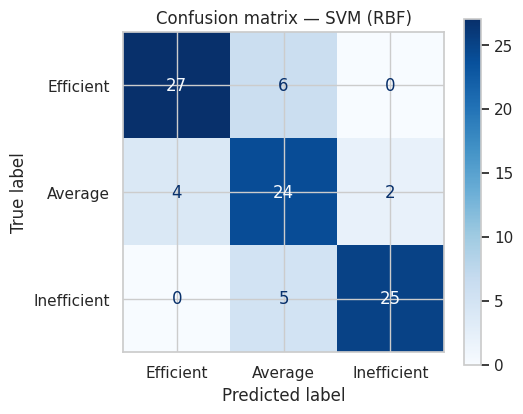

In [ ]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=["Efficient", "Average", "Inefficient"], cmap="Blues", ax=ax)
ax.set_title("Confusion matrix — SVM (RBF)")
plt.tight_layout()
plt.show()

In [ ]:
# Which input columns matter most? (drop in test accuracy when one column is shuffled)
importance = permutation_importance(best_model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring="accuracy")
ranking = pd.Series(importance.importances_mean, index=X_test.columns).sort_values(ascending=False)
print("Top 8 most important input columns (mean accuracy drop):")
print(ranking.head(8).round(4))

Top 8 most important input columns (mean accuracy drop):
height_mm               0.1263
brand                   0.1194
drivetrain              0.0919
torque_nm               0.0634
length_mm               0.0575
top_speed_kmh           0.0522
car_body_type           0.0280
acceleration_0_100_s    0.0237
dtype: float64



## Conclusion

**Model performance.** The SVM (RBF kernel) reached an **accuracy of 81.7%** on the unseen testing set (93 vehicles), with a macro-averaged F1-score of 0.820. Random guessing among three equal classes would give about 33%, so the model predicts a car's energy efficiency class well from its specifications alone. Its cross-validated accuracy on the training data was 79.7%, which is consistent with the test result.

**Per-class results**

- **Inefficient** cars (high Wh/km) have the highest precision (0.926, F1 0.877): when the model says a car is inefficient it is almost always right. Large, fast, all-wheel-drive vehicles and vans have distinctive profiles.
- **Efficient** cars are also recognised well (precision 0.871, recall 0.818, F1 0.844); 27 of 33 were found.
- **Average** is the hardest class (precision 0.686, F1 0.738). It lies between the other two classes, so cars near the class limits (146 and 171 Wh/km) are easily pushed to either side.
- The confusion matrix shows that the errors are almost all between neighbouring classes: no Efficient car was predicted as Inefficient, and no Inefficient car as Efficient. A wrong prediction is therefore usually only "one class off".

**What the model relies on.** The columns whose shuffling hurt accuracy the most were the vehicle height, the brand, the drivetrain, the torque and the length. This matches physical intuition: tall, long and powerful all-wheel-drive vehicles use more energy per kilometre than compact front-wheel-drive ones.

**Reliability and limitations**

- Training accuracy was 93.5% against 81.7% on the test set, so the model overfits somewhat.
- The test set is small (93 rows): one vehicle is about 1 percentage point, and the standard error of the accuracy is roughly 4 points.
- `range_km` was deliberately excluded because range is calculated from battery energy and efficiency; including it would let the model compute the answer instead of predicting it.
- Many rows are different trims of the same car model, so near-identical vehicles can appear in both the training and testing sets. This may make the result slightly optimistic compared with predicting a completely new model.
- Vehicle weight and aerodynamic drag, which strongly affect efficiency, are not in the dataset. Adding them would probably improve the results.
- Possible improvements: adding weight and drag data, predicting the exact Wh/km with a regression model, and grouping by car model when splitting.

**Overall**, the SVM can tell whether an electric car is efficient, average or inefficient with about 82% accuracy, and its mistakes are mostly between neighbouring classes.
